# Plotting pupillometric data for exploration

It is crucial to validate preprocessing steps by visually inspecting the results. Therefore, `pypillometry` implements several plotting functions that encourage active exploration of the dataset. Most of them are `matplotlib`-based and are available through the `.plot` attribute of each data object. For interactive exploration, there is also a separate viewer (see [Graphical tools](../user_guide/interactive.rst)).

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt

d = pp.PupilData.from_file("../../data/test.pd")

## Plotting pupil data

Each `PupilData` object has a `.plot` attribute that gives access to the plotting functions. `pupil_plot()` plots the complete pupil signal into the current figure, together with the events (grey lines):

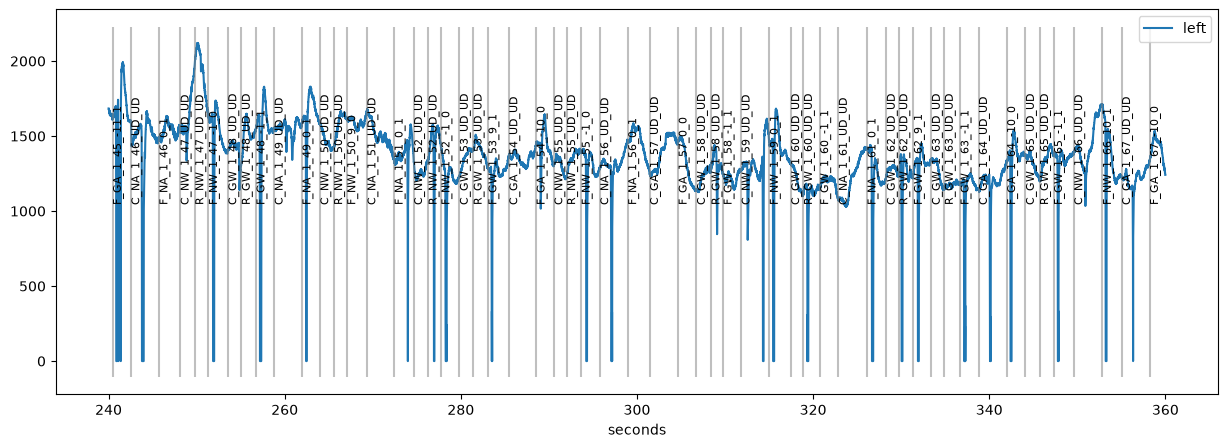

In [2]:
plt.figure(figsize=(15, 5))
d.plot.pupil_plot()

Often, the signal is too long to fit comfortably into one plot. Therefore, you can specify the range to plot with `plot_range=`. The range can be given with units, e.g., `(4.5, 4.7) * u.min` or `("260 sec", "280 sec")`. The units of the x-axis are set with `units=` (`"ms"`, `"sec"`, `"min"` or `"h"`):

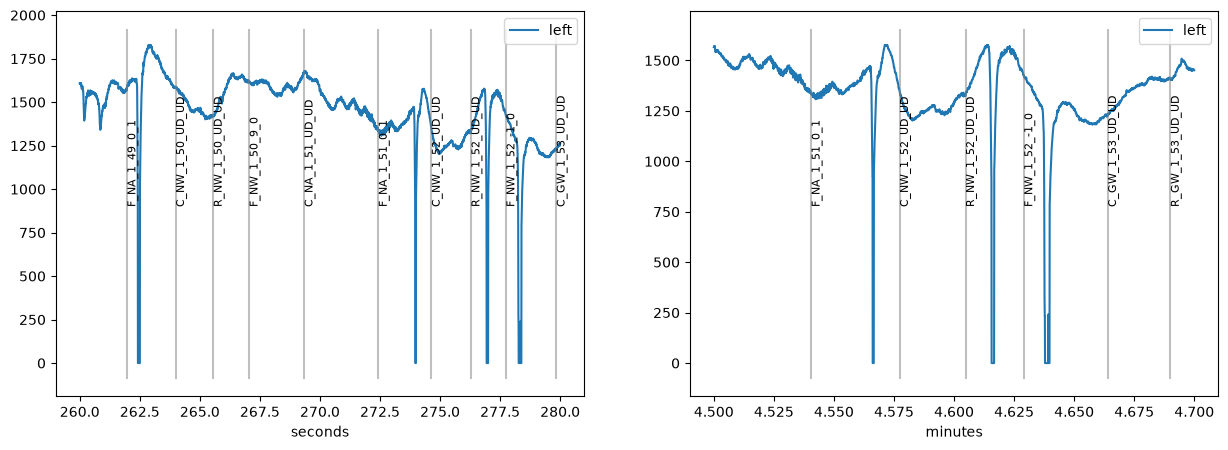

In [3]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
d.plot.pupil_plot(plot_range=(260, 280) * u.sec, units="sec")
plt.subplot(1, 2, 2)
d.plot.pupil_plot(plot_range=(4.5, 4.7) * u.min, units="min")

Note that the y-axis goes all the way to zero because missing data is coded as `0` in this dataset.

When we detect blinks (see the [blinks notebook](blinks.ipynb)) with `apply_mask=True`, the blinks are masked and highlighted in red:

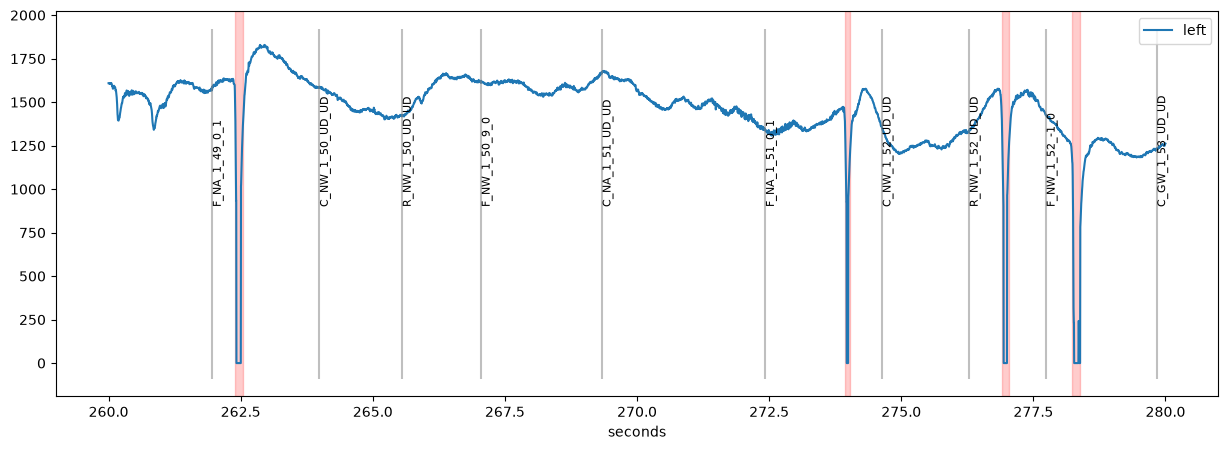

In [4]:
d.pupil_blinks_detect(vel_onset=-15, apply_mask=True)

plt.figure(figsize=(15, 5))
d.plot.pupil_plot(plot_range=(260, 280) * u.sec)

## Comparing datasets

To compare two versions of a dataset, for example before and after preprocessing, we can plot both into the same figure. The argument `label_prefix` distinguishes them in the legend and `style` sets the line style:

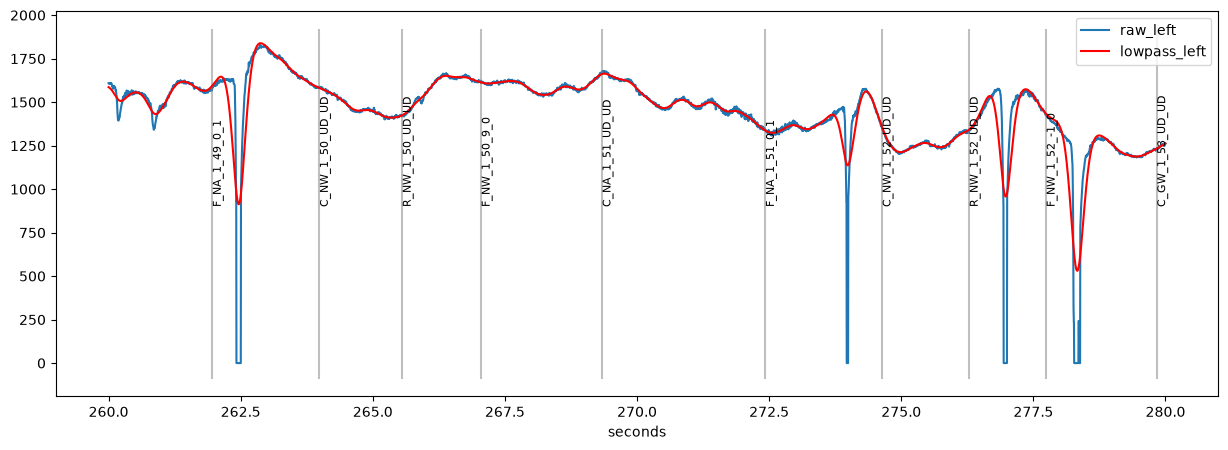

In [5]:
d2 = d.pupil_lowpass_filter(cutoff=2, inplace=False)

plt.figure(figsize=(15, 5))
d.plot.pupil_plot(plot_range=(260, 280) * u.sec, label_prefix="raw", show_blinks=False)
d2.plot.pupil_plot(plot_range=(260, 280) * u.sec, label_prefix="lowpass",
                   style={"color": "red"}, show_events=False, show_blinks=False)

The low-pass filter smears the blinks into the neighbouring signal. This is why blinks should be interpolated before filtering (see the [blinks notebook](blinks.ipynb)).

## Plotting all variables

`pupil_plot()` is specific to pupil data. `plot_timeseries()` plots all variables (pupil, gaze coordinates, and any variable created during processing), one subplot per variable. Here we use an `EyeData` object which contains both pupil and gaze data:

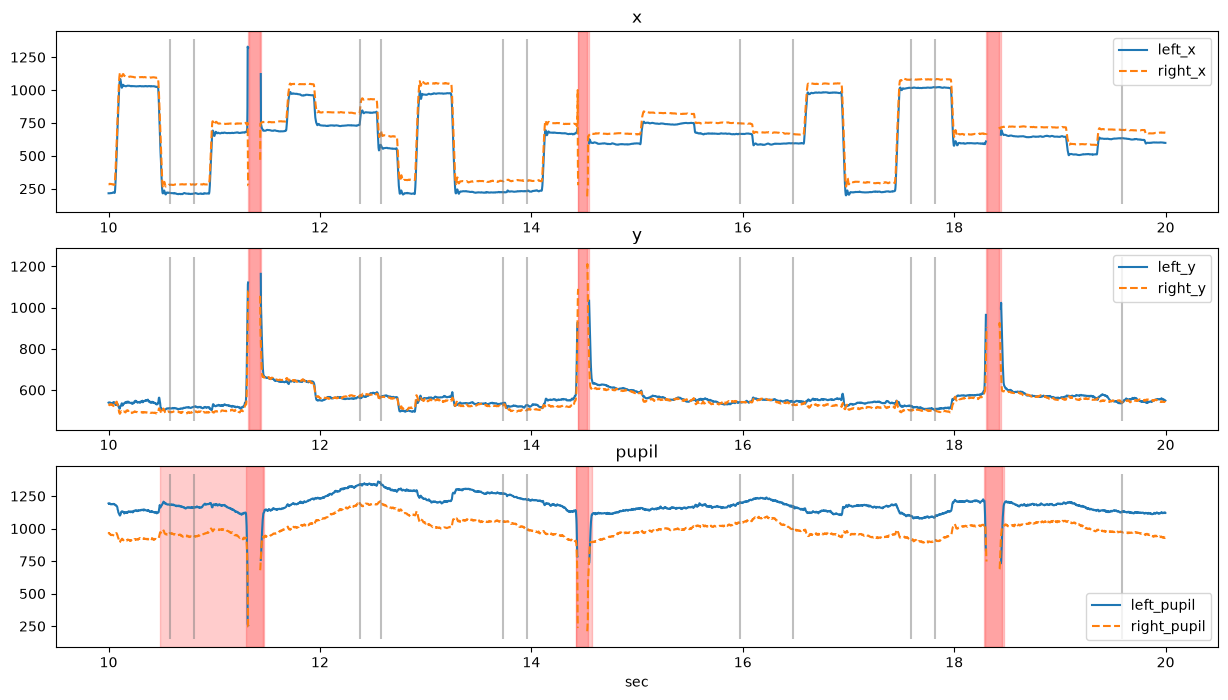

In [6]:
de = pp.get_example_data("rlmw_002_short")
de.pupil_blinks_detect(apply_mask=True)

plt.figure(figsize=(15, 8))
de.plot.plot_timeseries(plot_range=(10, 20) * u.sec, units="sec")

`GazeData` and `EyeData` objects also have gaze-specific plots, e.g., a heatmap or a scanpath:

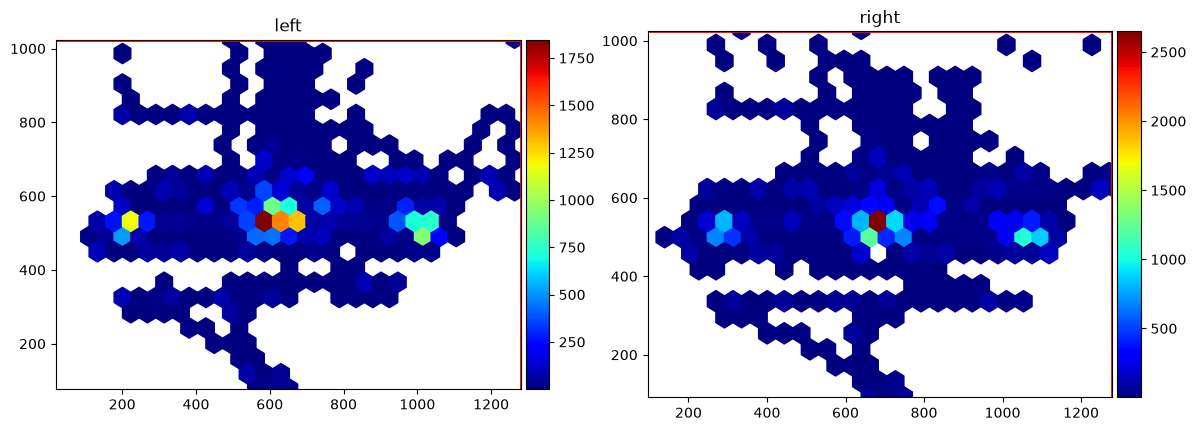

In [7]:
plt.figure(figsize=(14, 5))
de.plot.plot_heatmap()

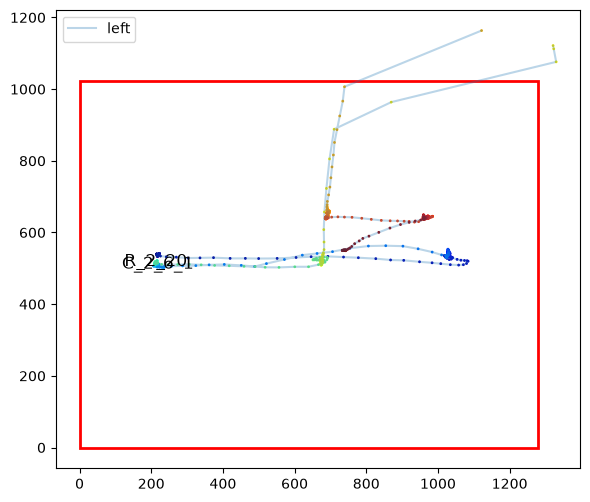

In [8]:
de.plot.plot_scanpath(plot_range=(10, 12) * u.sec, eyes="left", figsize=(6, 6))

## `pupil_plot_segments()`

It is usually a good idea to browse through the whole recording before and after preprocessing. This can be useful for tweaking preprocessing parameters or for detecting gross artifacts. `pupil_plot_segments()` produces as many plots as necessary, each displaying a part of the data (argument `interv`, e.g., 30 seconds).

By default, it returns a list of `matplotlib` figures that can be inspected:

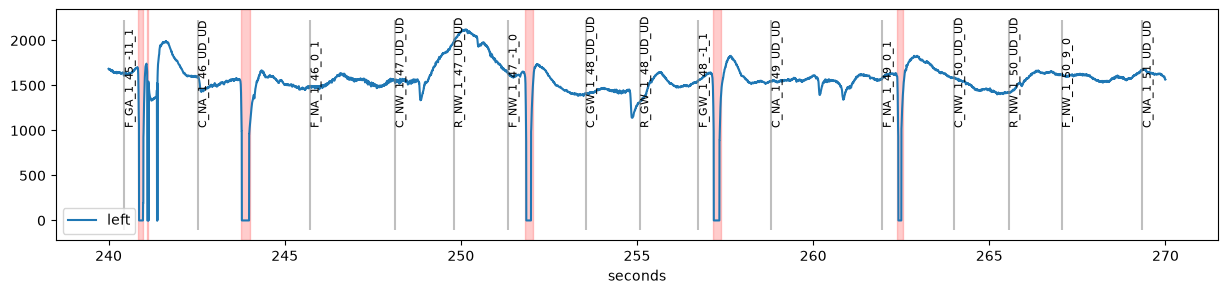

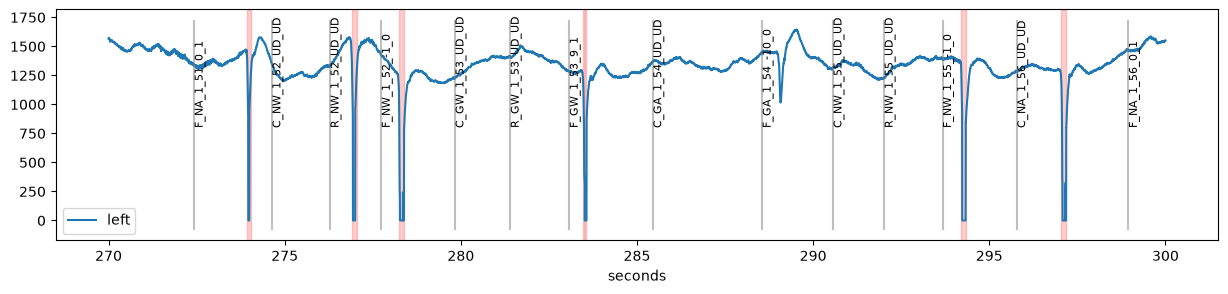

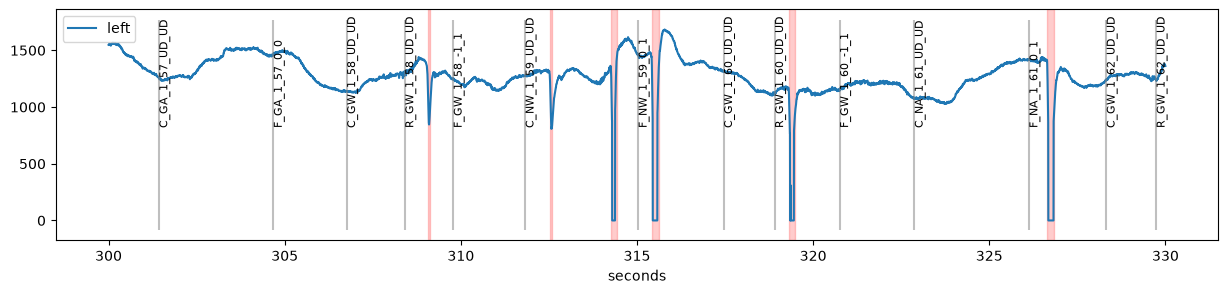

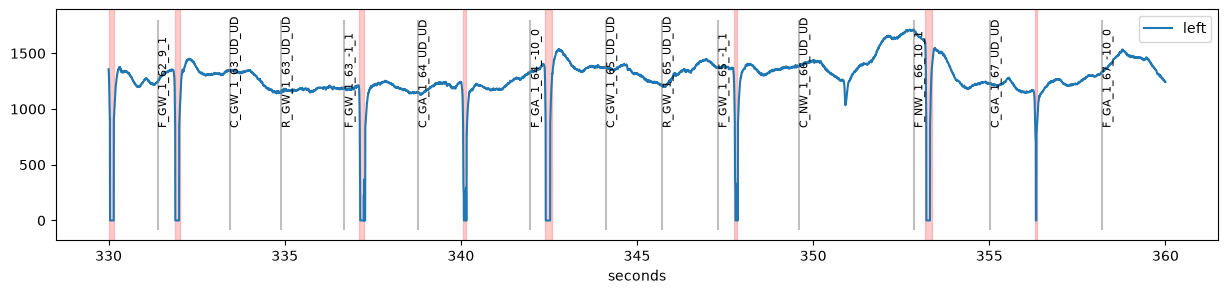

In [9]:
figs = d.plot.pupil_plot_segments(interv=30 * u.sec, units="sec", figsize=(15, 3))

Instead, the plots can be saved to a (multi-page) PDF file for later inspection:

```python
d.plot.pupil_plot_segments(pdf_file="segments.pdf")
```

`plot_timeseries_segments()` does the same for all variables.

## Inspecting blinks and other intervals

Blinks can be tricky to interpolate. To make this easier, `plot_blinks()` plots all detected blinks, each in its own panel. It works similar to `pupil_plot_segments()`, i.e., it returns a list of figures or saves them to a PDF file. Each panel shows the index of the blink which allows you to locate individual blinks in the full dataset.

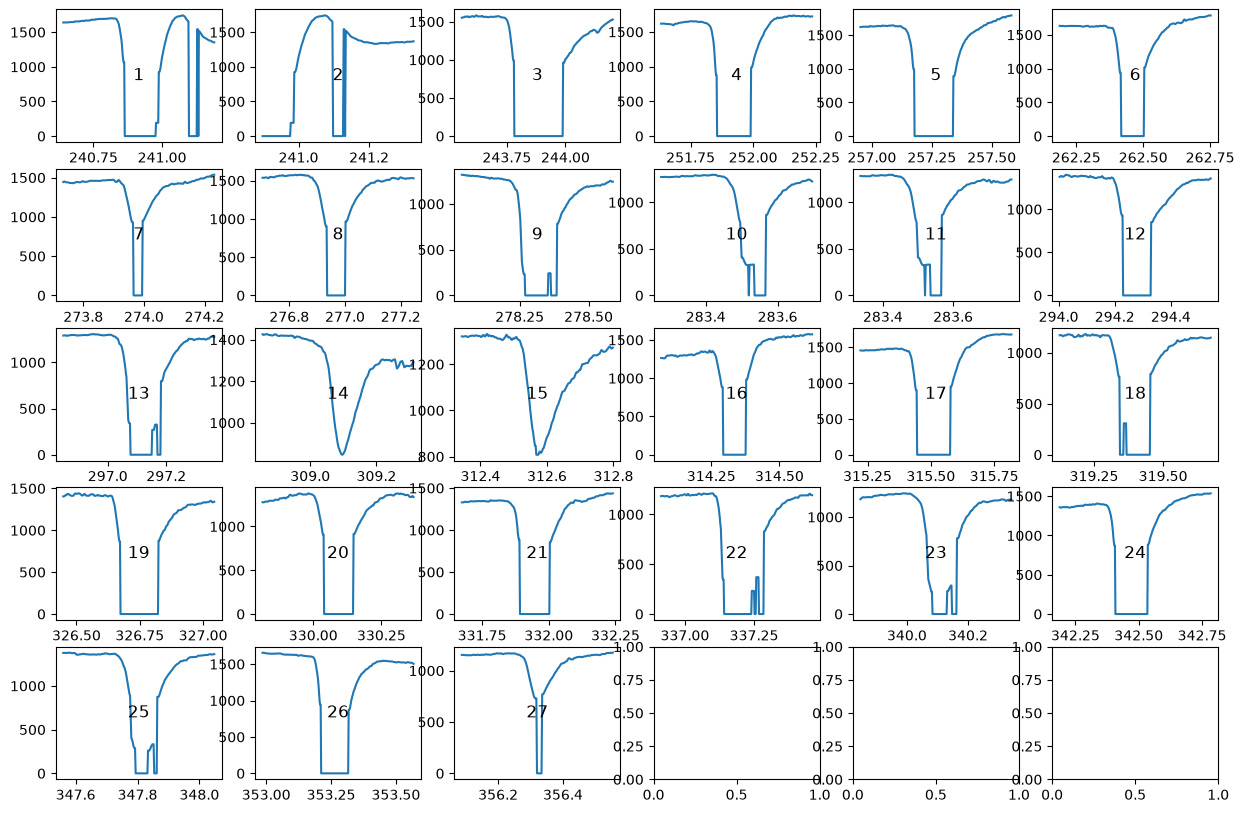

In [10]:
d.plot.plot_blinks(nrow=5, ncol=6, figsize=(15, 10), units="sec");

`plot_intervals()` does the same for any `Intervals` object, for example the intervals around events returned by `get_intervals()`:

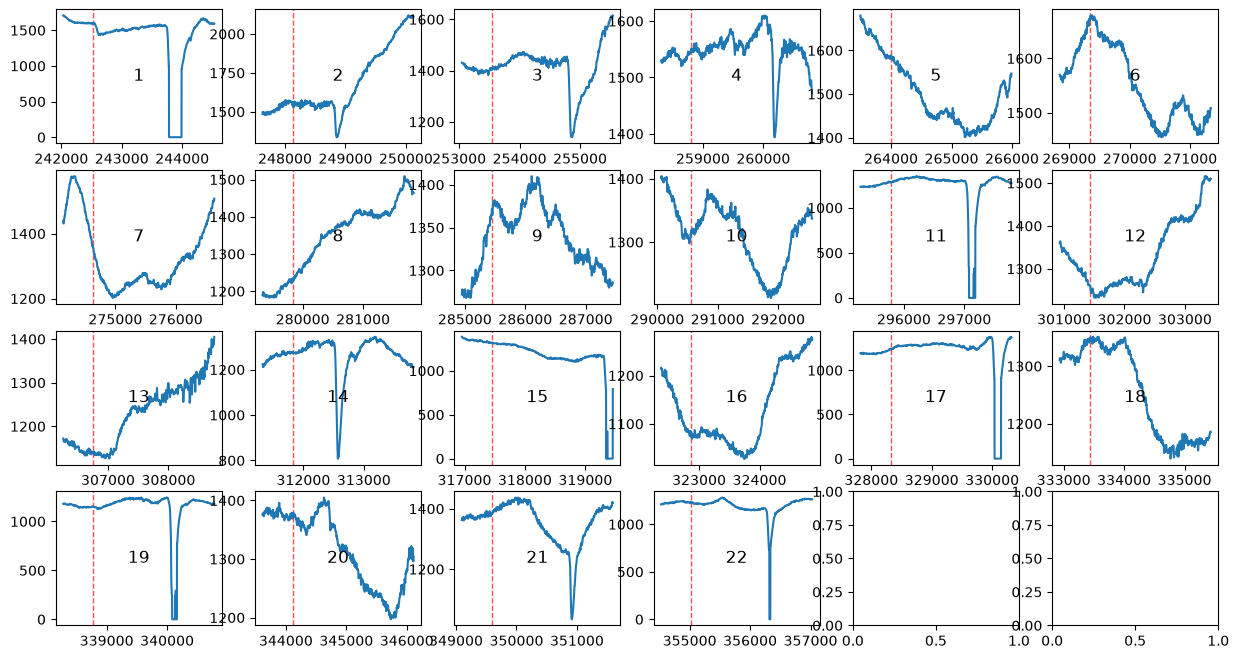

In [11]:
cues = d.get_intervals("C_", interval=(-500, 2000) * u.ms)
d.plot.plot_intervals(cues, nrow=4, ncol=6, figsize=(15, 8));

Finally, `plot_masked()` gives an overview of which parts of the data are masked for each eye and variable:

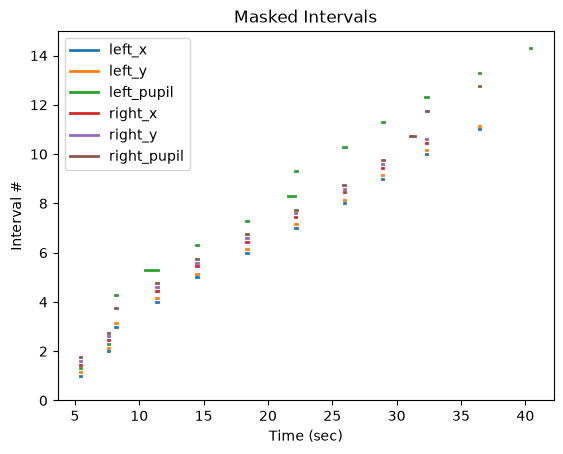

In [12]:
de.plot.plot_masked(units="sec");

## Interactive plotting

For interactive exploration, `pp.view(d)` opens the data in a separate window in which you can zoom and scroll through the recording, and `pp.tweak(d)` lets you adjust the parameters of preprocessing steps while seeing the results. See [Graphical tools](../user_guide/interactive.rst) for details. Alternatively, you can switch `matplotlib` to a non-inline backend (e.g., with `%matplotlib qt`) to zoom and pan in any of the plots above.